# FALCON H1 — Training a velocity decoder

End-to-end example:
- `FanFalconH1` **Study**
- `Spikes` + `LinearVelocitySeries` **events**
- `SpikesExtractor` + `BehavioralSeriesExtractor`
- **Segmenter** of sliding windows
- a simple **sequence-to-sequence** model that maps binned spikes to hand velocity, `(B, n_units, T) → (B, 3, T)`

The target is **linear velocity** `(vx, vy, vz)` at 50 Hz, same grid as the binned spikes, so input and target time axes line up. Swap `event_types` to decode any other stream (`PositionSeries`, `GraspSeries`, …) with no other change.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

import neuralset as ns
from neuralset.extractors import SpikesExtractor
import neuralshed.events, neuralshed.extractors      # register custom types
from neuralshed.extractors import BehavioralSeriesExtractor
from neuralshed.datasets.fan_h1 import study
from neuralshed.datasets.utils import dataset_dir

torch.manual_seed(0)
SESSIONS = [0, 1, 2, 3, 4, 5]              # six held-in-calib sessions
FS, WIN_S, STRIDE_S = 50.0, 1.0, 1.0       # 50 Hz, 1 s sliding windows (T=50)
CACHE_DIR = dataset_dir("fan_h1") / "cache"   # extractor disk cache: <NEURALSHED_DATA_ROOT>/fan_h1/cache/

events = study.FanFalconH1(
    path=dataset_dir("fan_h1/data"), query=f"timeline_index in {SESSIONS}"
).run()
print("sessions:", events.timeline.nunique(), "| types:", events.type.value_counts().to_dict())

  0%|          | 0/6 [00:00<?, ?it/s]

 17%|█▋        | 1/6 [00:00<00:03,  1.41it/s]

 50%|█████     | 3/6 [00:00<00:00,  4.42it/s]

 83%|████████▎ | 5/6 [00:00<00:00,  7.02it/s]

100%|██████████| 6/6 [00:00<00:00,  6.01it/s]

sessions: 6 | types: {'Action': 529, 'Stimulus': 427, 'Intertrial': 11, 'Spikes': 6, 'PositionSeries': 6, 'OrientationSeries': 6, 'GraspSeries': 6, 'LinearVelocitySeries': 6, 'AngularVelocitySeries': 6, 'GraspVelocitySeries': 6}


## 1. Segment the sessions into windows

Anchor on each session's whole-session `Spikes` event and slide a window across it.
Two extractors fill the batch — `SpikesExtractor` → `(n_units, T)` and
`BehavioralSeriesExtractor(event_types="LinearVelocitySeries")` → `(3, T)`, both at 50 Hz.

Both extractors cache their per-session read via `exca.MapInfra` to a **disk cache** at
`<NEURALSHED_DATA_ROOT>/fan_h1/cache/` (`keep_in_ram=False` bounds RAM), so pulling many
sessions and windows reuses one read per stream. For small data, switch to
`keep_in_ram=True` (in-process, no disk).

In [2]:
# Disk cache (bounds RAM). For small data, swap for dict(keep_in_ram=True) (in-process, no disk).
cache = dict(folder=CACHE_DIR, keep_in_ram=False)
segmenter = ns.dataloader.Segmenter(
    extractors={
        "input": SpikesExtractor(frequency=FS, infra=cache),
        "target": BehavioralSeriesExtractor(event_types="LinearVelocitySeries", frequency=FS, infra=cache),
    },
    trigger_query="type == 'Spikes'",   # anchor on the whole-session Spikes event
    start=0.0, duration=WIN_S, stride=STRIDE_S,
)
ds = segmenter.apply(events)
ds.prepare()
print(ds)

2026-06-26 09:49:51 - INFO - neuralset.dataloader:222 - Preparing extractor: SpikesExtractor


  0%|          | 0/6 [00:00<?, ?it/s]

 33%|███▎      | 2/6 [00:00<00:00, 11.31it/s]

 83%|████████▎ | 5/6 [00:00<00:00, 18.38it/s]

100%|██████████| 6/6 [00:00<00:00, 16.46it/s]

2026-06-26 09:49:52 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor


  0%|          | 0/6 [00:00<?, ?it/s]

 83%|████████▎ | 5/6 [00:00<00:00, 42.38it/s]

100%|██████████| 6/6 [00:00<00:00, 39.48it/s]

SegmentDataset(1086 segments, 1.00s, extractors: input, target)


## 2. Materialize and split

`load_all()` runs the extractors once and returns the whole dataset as tensors.
Windows are non-overlapping, so a random 80/20 split has no train/val leakage.

In [3]:
batch = ds.load_all()
X = batch.data["input"].float()     # (N, n_units, T)
Y = batch.data["target"].float()    # (N, 3, T)
N = X.shape[0]

perm = torch.randperm(N, generator=torch.Generator().manual_seed(0))
n_tr = int(0.8 * N)
tr, va = perm[:n_tr], perm[n_tr:]
Xtr, Ytr, Xva, Yva = X[tr], Y[tr], X[va], Y[va]
print("X", tuple(X.shape), "| Y", tuple(Y.shape), "| train/val:", len(tr), len(va))

X (1086, 176, 50) | Y (1086, 3, 50) | train/val: 868 218


## 3. Normalize

Per-channel z-score using **train** statistics (decoding targets are standardized
and inverted back to real units for reporting).

In [4]:
x_mu, x_sd = Xtr.mean((0, 2), keepdim=True), Xtr.std((0, 2), keepdim=True) + 1e-6
y_mu, y_sd = Ytr.mean((0, 2), keepdim=True), Ytr.std((0, 2), keepdim=True) + 1e-6
nx = lambda x: (x - x_mu) / x_sd
ny = lambda y: (y - y_mu) / y_sd
Xtr_n, Ytr_n, Xva_n, Yva_n = nx(Xtr), ny(Ytr), nx(Xva), ny(Yva)

## 4. A simple seq2seq decoder

A small temporal CNN with dropout: `(B, n_units, T) → (B, 3, T)`, one velocity vector
per time bin. `neuraltrain.models.SimpleConvModel` is the production drop-in.

In [5]:
class VelocityDecoder(nn.Module):
    def __init__(self, c_in, c_out, hidden=96, k=7, p_drop=0.1):
        super().__init__()
        pad = k // 2
        self.net = nn.Sequential(
            nn.Conv1d(c_in, hidden, k, padding=pad), nn.ReLU(), nn.Dropout(p_drop),
            nn.Conv1d(hidden, hidden, k, padding=pad), nn.ReLU(), nn.Dropout(p_drop),
            nn.Conv1d(hidden, c_out, 1),
        )

    def forward(self, x):
        return self.net(x)        # (B, c_out, T)

model = VelocityDecoder(X.shape[1], Y.shape[1])

## 5. Train

Minibatch SGD with weight decay; we keep the weights at their best validation MSE
(a light guard against overfitting). The `val MSE` here is on the **train-normalized**
target, so across sessions it sits near/above 1.0 — read the honest generalization
numbers as **R²** in §6, not this loss.

In [6]:
train_loader = DataLoader(TensorDataset(Xtr_n, Ytr_n), batch_size=64, shuffle=True)
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.MSELoss()

best_val, best_state = float("inf"), None
for epoch in range(80):
    model.train()
    for xb, yb in train_loader:
        opt.zero_grad(); loss_fn(model(xb), yb).backward(); opt.step()
    model.eval()
    with torch.no_grad():
        tl = loss_fn(model(Xtr_n), Ytr_n).item()
        vl = loss_fn(model(Xva_n), Yva_n).item()
    if vl < best_val:
        best_val, best_state = vl, {k: v.clone() for k, v in model.state_dict().items()}
    if (epoch + 1) % 20 == 0:
        print(f"epoch {epoch+1:2d}  train MSE {tl:.3f}  val MSE {vl:.3f}  (best {best_val:.3f})")

model.load_state_dict(best_state)        # restore best-validation weights
print("best val MSE:", round(best_val, 3))

epoch 20  train MSE 0.070  val MSE 1.134  (best 1.117)


epoch 40  train MSE 0.035  val MSE 1.137  (best 1.112)


epoch 60  train MSE 0.030  val MSE 1.116  (best 1.106)


epoch 80  train MSE 0.023  val MSE 1.119  (best 1.106)
best val MSE: 1.106


## 6. Evaluate — correlation and R² on validation

In [7]:
model.eval()
with torch.no_grad():
    pred = model(Xva_n) * y_sd + y_mu          # back to original units
P  = pred.permute(1, 0, 2).reshape(3, -1).numpy()
Tt = Yva.permute(1, 0, 2).reshape(3, -1).numpy()
for i, d in enumerate(["x", "y", "z"]):
    r = np.corrcoef(P[i], Tt[i])[0, 1]
    r2 = 1 - ((Tt[i] - P[i]) ** 2).sum() / ((Tt[i] - Tt[i].mean()) ** 2).sum()
    print(f"v{d}:  corr {r:.3f}   R2 {r2:.3f}")

vx:  corr 0.367   R2 0.127
vy:  corr 0.436   R2 0.189
vz:  corr 0.408   R2 0.163


## 7. Decoded vs true velocity

A qualitative view over a contiguous span of the first session (time-ordered windows).

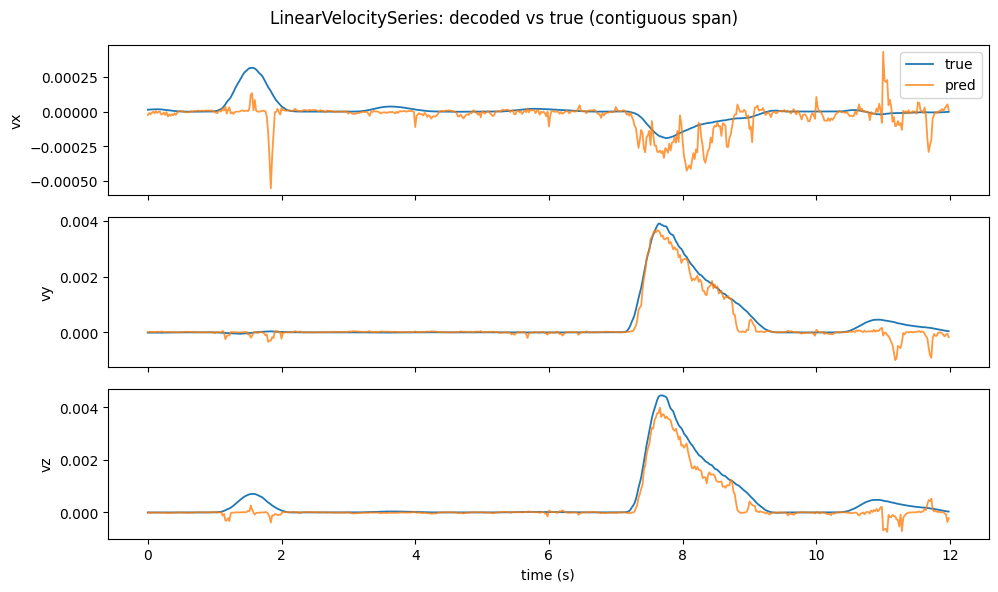

In [8]:
K = 12                                          # first 12 s of session 0 (contiguous)
with torch.no_grad():
    pc = (model(nx(X[:K])) * y_sd + y_mu).permute(1, 0, 2).reshape(3, -1).numpy()
tc = Y[:K].permute(1, 0, 2).reshape(3, -1).numpy()
tt = np.arange(pc.shape[1]) / FS
fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
for i, (ax, d) in enumerate(zip(axes, ["x", "y", "z"])):
    ax.plot(tt, tc[i], label="true", lw=1.3)
    ax.plot(tt, pc[i], label="pred", lw=1.3, alpha=0.8)
    ax.set_ylabel(f"v{d}")
axes[0].legend(loc="upper right"); axes[-1].set_xlabel("time (s)")
fig.suptitle("LinearVelocitySeries: decoded vs true (contiguous span)")
plt.tight_layout(); plt.show()